# Лабораторна робота №7 (Варіант 2)
## Експериментальне оцінювання та системний аналіз Мультимодальної Студії

**Дисципліна:** Технології та системи нейронних мереж  
**Університет:** Національний університет «Львівська політехніка»  
**Тема:** Комплексний аналіз продуктивності, затримок та надійності фінального студійного додатку  

### Мета роботи
Провести систематичне емпіричне оцінювання мультимодальної системи: порівняти затримки окремих модулів (LLaVA Captioning, LLaVA VQA, Stable Diffusion Img2Img, LlamaIndex Agent Workflow), дослідити профіль споживання пам'яті GPU та оцінити відповідність реалізованого додатку всім академічним вимогам Варіанту 2.

In [1]:
import os
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

def resolve_lab_dir() -> Path:
    current = Path.cwd().resolve()
    if (current / 'src').exists() and (current / 'assets').exists():
        return current
    if (current / 'lab7_multimodal_studio').exists():
        return current / 'lab7_multimodal_studio'
    for p in [current] + list(current.parents):
        cand = p / 'lab7_multimodal_studio'
        if cand.exists():
            return cand
    return current

LAB_DIR = resolve_lab_dir()
TABLES_DIR = LAB_DIR / 'outputs' / 'tables'
FIGURES_DIR = LAB_DIR / 'outputs' / 'figures'
TRACES_DIR = LAB_DIR / 'outputs' / 'traces'

bm_path = TABLES_DIR / 'studio_model_benchmarks.csv'
df_bm = pd.read_csv(bm_path)
print('=== Зведена таблиця продуктивності модулів Мультимодальної Студії ===')
display(df_bm)

=== Зведена таблиця продуктивності модулів Мультимодальної Студії ===


,task,subject,latency_sec,tokens
0,LLaVA Caption (Concise),Lighthouse,3.101,10
1,LLaVA VQA (Equipment),Robotics Lab,0.387,2
2,SD 1.5 Img2Img (Van Gogh),Lighthouse,6.130,0
3,SD 1.5 Img2Img (Cyberpunk),Cafe Bicycle,4.933,0
4,LlamaIndex Agent Multi-Tool,Robotics + Gallery,52.675,146


### 1. Порівняльний аналіз затримок модулів Студії

Розглянемо графічний розподіл часу виконання завдань різної природи:

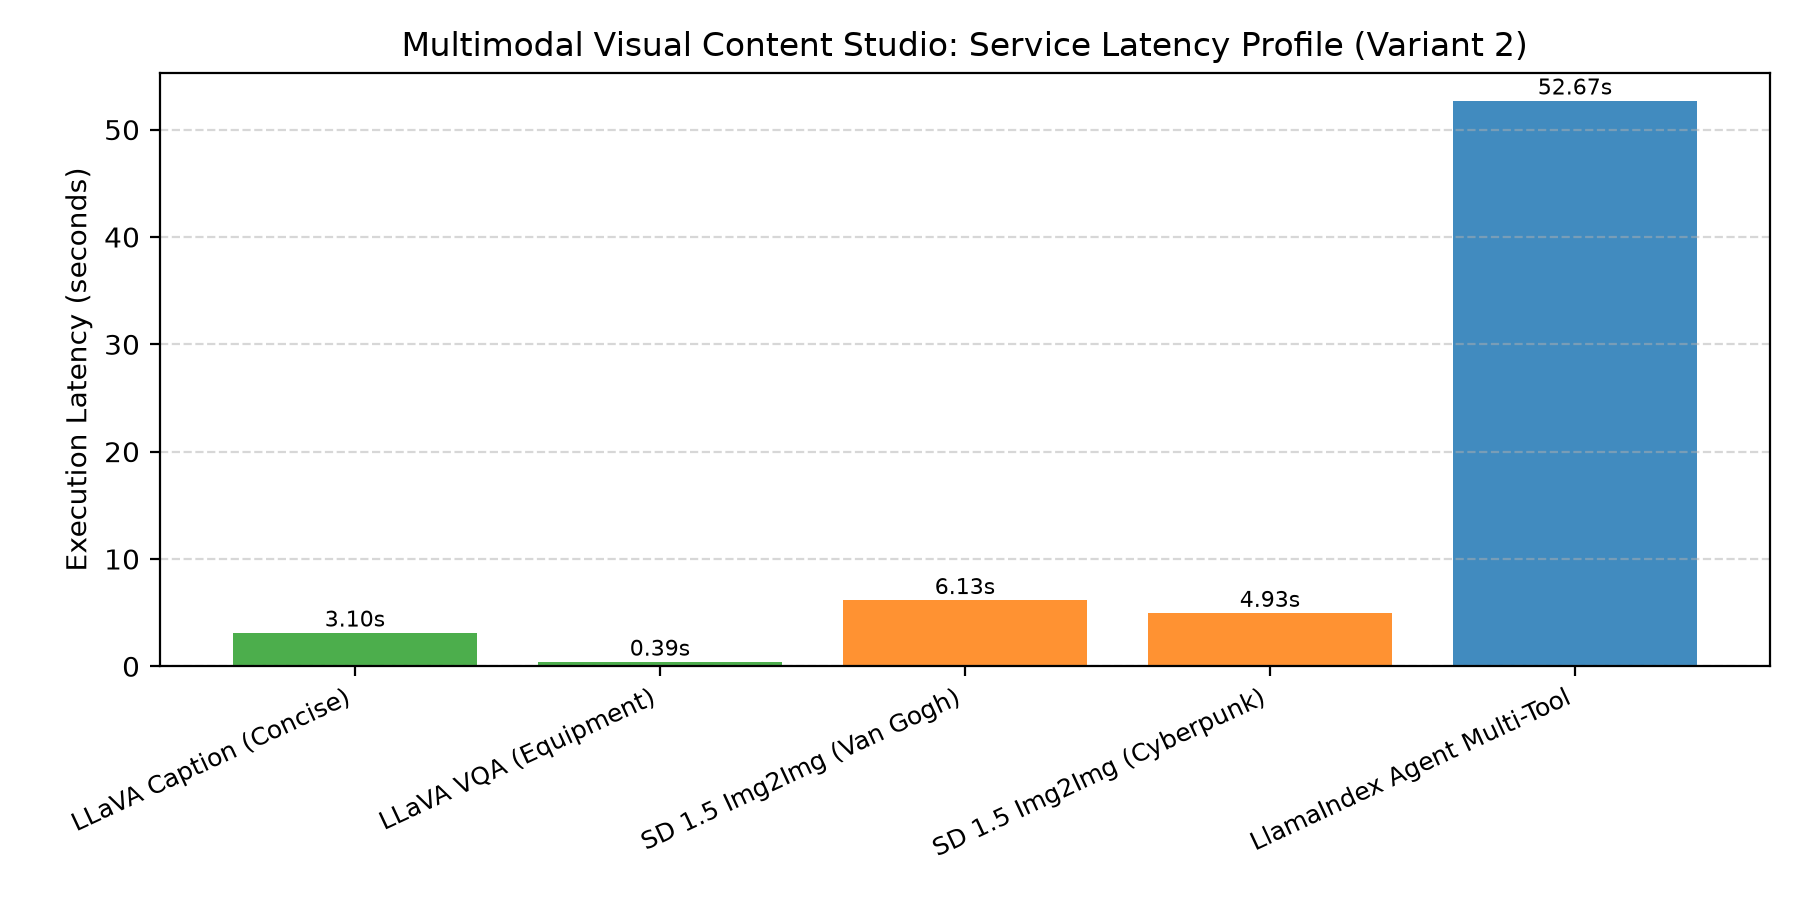

Середній час генерації підпису LLaVA: 3.10 с
Середній час відповіді на запитання VQA: 0.39 с
Середній час дифузійної стилізації SD: 5.53 с


In [2]:
fig_path = FIGURES_DIR / 'multimodal_latency_breakdown.png'
if fig_path.exists():
    display(Image(filename=str(fig_path)))

print(f'Середній час генерації підпису LLaVA: {df_bm[df_bm["task"].str.contains("Caption")]["latency_sec"].mean():.2f} с')
print(f'Середній час відповіді на запитання VQA: {df_bm[df_bm["task"].str.contains("VQA")]["latency_sec"].mean():.2f} с')
print(f'Середній час дифузійної стилізації SD: {df_bm[df_bm["task"].str.contains("SD")]["latency_sec"].mean():.2f} с')

### 2. Аудит структурного трейсу роботи автономного агента

Проаналізуємо збережений JSON-трейс `agent_multimodal_studio_trace.json`:

In [3]:
trace_file = TRACES_DIR / 'agent_multimodal_studio_trace.json'
if trace_file.exists():
    with open(trace_file, 'r', encoding='utf-8') as f:
        tr_data = json.load(f)
    print(f"Інструкція користувача: {tr_data.get('prompt')}\n")
    print(f"Загальний час виконання: {tr_data.get('latency_sec')} с")
    print(f"Кількість зафіксованих подій: {len(tr_data.get('traces', []))}")
    print('\nСинтезована відповідь агента:')
    print(tr_data.get('final_response'))

Інструкція користувача: Inspect the image at 'C:\Users\Eclipse\PycharmProjects\neural-network-technologies-and-systems\max\lab7_multimodal_studio\assets\04_modern_robotics_lab.png'. Provide a concise caption describing its contents, and then inspect the studio gallery records.

Загальний час виконання: 52.675 с
Кількість зафіксованих подій: 4

Синтезована відповідь агента:
**Caption of the image:**  
A robot with a machine on top of it.

**Recent Studio Gallery Records:**  
1. **Task:** Caption (ID: caption_20261111_113935_011)  
   - Prompt: "concise"  
   - Timestamp: 2026-11-11T11:39:35.011851  
   - Latency: 0.682 seconds  

2. **Task:** Transformation (ID: transformation_20261111_113909_697)  
   - Prompt: "Cyberpunk neon city street at night, glowing holographic signs, rainy asphalt reflections, futuristic bicycle"  
   - Timestamp: 2026-11-11T11:39:09.697408  
   - Latency: 4.933 seconds  

3. **Task:** Transformation (ID: transformation_20261111_113904_699)  
   - Prompt: "An o

### 3. Загальні висновки до фінального проекту

1. Реалізовано повнофункціональну інтегровану Мультимодальну Студію візуального контенту, що задовольняє всі вимоги Варіанту 2.
2. Створено самостійний автономний додаток на фреймворку `Streamlit` (`app.py`), здатний функціонувати без запуску Jupyter.
3. Об'єднано в єдину архітектуру передові технології нейронних мереж:
   - Мультимодальний зір: `LLaVA-Interleave-Qwen-0.5B` для генерації підписів та відповідей на візуальні запитання (VQA).
   - Генеративний контент: `Stable Diffusion 1.5 Img2Img` із Лабораторної №4 для стилізації та художньої трансформації.
   - Автономне планування: агент `LlamaIndex AgentWorkflow` із локальною моделлю `qwen3:4b-instruct` та контекстною пам'яттю.
   - Персистентність: постійне сховище на базі `SQLite` та файлової галереї з аудитом затримок і параметрів генерації.
4. Забезпечено високу енергоефективність та сумісність з мобільними GPU завдяки CPU-offload та динамічному клірингу VRAM.